# CocoAnalytica: F1 Score and Confusion Matrix

This notebook reports the balanced evaluation for the TensorFlow Lite model used by the website. It uses exactly **20 images per condition** (80 images total). The training and per-image test-folder score workflow remains in `model.ipynb`.

## Evaluation composition

The table includes all approved external photos first, then fills each condition to 20 with original held-out internal test images. This produces a balanced 20-per-condition comparison without duplicating any image.

| Condition | Approved external | Held-out internal test | Total |
| --- | ---: | ---: | ---: |
| Healthy | 12 | 8 | 20 |
| Yellowing | 12 | 8 | 20 |
| Coconut Scale Insect | 5 | 15 | 20 |
| Rhinoceros Beetle | 2 | 18 | 20 |

`Y04` is retained in the approval archive but excluded from the score because it is an exact duplicate of another Yellowing image. This is a balanced combined evaluation, not an external-only benchmark.

In [ ]:
from __future__ import annotations
import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display, Markdown

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / 'backend/app/ml/predictor.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT / 'backend'))
sys.path.insert(0, str(PROJECT_ROOT / 'backend/scripts'))
from notebook_workflow import CLASSES, evaluate_api, external_test_status, metrics_for

MODEL_DIR = PROJECT_ROOT / 'Thesis AI Model'
OUTPUT_DIR = MODEL_DIR / 'model_outputs'
EXTERNAL_TEST_DIR = MODEL_DIR / 'external_test_set'
INTERNAL_TEST_DATASET_DIR = MODEL_DIR / 'notebook_dataset' / '4e327ceeeb11'
TFLITE_PATH = OUTPUT_DIR / 'coconut_leaf_multilabel_cnn.tflite'
LABEL_CONFIG_PATH = OUTPUT_DIR / 'label_config.json'
TARGET_IMAGES_PER_CLASS = 20
CONFUSION_MATRIX_PNG = OUTPUT_DIR / 'confusion_matrix_balanced_20_per_class.png'

In [ ]:
def display_f1_score_table(report, title):
    lines = [
        f'### F1 Score Table - {title}',
        '',
        '| Condition | Precision | Recall | F1 score | Images |',
        '| --- | ---: | ---: | ---: | ---: |',
    ]
    for label in CLASSES:
        row = report['per_class'][label]
        lines.append(
            f"| {label.replace('_', ' ')} | {row['precision']:.1%} | {row['recall']:.1%} | "
            f"**{row['f1']:.1%}** | {row['support']} |"
        )
    lines.extend([
        '',
        '| Overall measure | Score |',
        '| --- | ---: |',
        f"| Accuracy | **{report['accuracy']:.1%}** |",
        f"| Macro F1 | **{report['macro_f1']:.1%}** |",
        f"| Weighted F1 | **{report['weighted_f1']:.1%}** |",
    ])
    display(Markdown('\n'.join(lines)))


def display_confusion_matrix(report, title, output_path=CONFUSION_MATRIX_PNG):
    matrix = np.asarray(report['confusion_matrix'], dtype=int)
    labels = ['Healthy', 'Yellowing', 'Coconut Scale\nInsect', 'Rhinoceros\nBeetle']
    fig, ax = plt.subplots(figsize=(9, 7), dpi=160)
    image = ax.imshow(matrix, cmap='YlGn', vmin=0, vmax=max(int(matrix.max()), 1))
    colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    colorbar.set_label('Number of images', rotation=270, labelpad=18)
    ax.set(
        xticks=np.arange(len(labels)),
        yticks=np.arange(len(labels)),
        xticklabels=labels,
        yticklabels=labels,
        xlabel='Predicted condition',
        ylabel='Actual condition',
        title=f'Confusion Matrix: {title}',
    )
    ax.xaxis.set_label_position('top')
    ax.xaxis.tick_top()
    ax.tick_params(axis='x', pad=10)
    midpoint = matrix.max() / 2
    for row_index, row in enumerate(matrix):
        row_total = int(row.sum())
        for column_index, value in enumerate(row):
            percentage = value / row_total if row_total else 0.0
            color = 'white' if value > midpoint else '#173d25'
            ax.text(
                column_index, row_index, f'{value}\n{percentage:.0%}', ha='center', va='center',
                color=color, fontweight='bold', fontsize=11,
            )
    ax.set_xticks(np.arange(-0.5, len(labels), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(labels), 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='minor', bottom=False, left=False)
    fig.text(0.5, 0.02, 'Cell labels show count and percentage of the actual-condition row.', ha='center', color='#365342')
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(output_path, bbox_inches='tight', facecolor='white')
    display(fig)
    plt.close(fig)


def build_balanced_report(internal_rows, external_rows):
    """Use all approved external photos, then fill to 20 per class from held-out test images."""
    selected, composition = [], {}
    for label in CLASSES:
        external_for_label = sorted(
            (row for row in external_rows if row['actual'] == label), key=lambda row: row['file']
        )
        if len(external_for_label) > TARGET_IMAGES_PER_CLASS:
            raise ValueError(f'Too many external images for {label}; define a new selection policy.')
        internal_for_label = sorted(
            (row for row in internal_rows if row['actual'] == label), key=lambda row: row['file']
        )
        required_internal = TARGET_IMAGES_PER_CLASS - len(external_for_label)
        if len(internal_for_label) < required_internal:
            raise ValueError(f'Not enough held-out test images to complete {label}.')
        selected.extend({**row, 'evaluation_source': 'approved_external'} for row in external_for_label)
        selected.extend(
            {**row, 'evaluation_source': 'internal_holdout'}
            for row in internal_for_label[:required_internal]
        )
        composition[label] = {
            'approved_external': len(external_for_label),
            'internal_holdout': required_internal,
            'total': TARGET_IMAGES_PER_CLASS,
        }
    report = metrics_for(
        [CLASSES.index(row['actual']) for row in selected],
        [CLASSES.index(row['predicted']) for row in selected],
    )
    report.update(
        benchmark='balanced combined evaluation with 20 images per condition',
        benchmark_status='provisional combined evaluation; not an independent external-only benchmark',
        target_images_per_class=TARGET_IMAGES_PER_CLASS,
        composition_by_class=composition,
        internal_test_images=sum(row['evaluation_source'] == 'internal_holdout' for row in selected),
        selected_external_images=sum(row['evaluation_source'] == 'approved_external' for row in selected),
        predictions=selected,
    )
    return report

### F1 Score Table - Balanced Evaluation (20 Images per Condition)

| Condition | Precision | Recall | F1 score | Images |
| --- | ---: | ---: | ---: | ---: |
| Healthy | 52.6% | 50.0% | **51.3%** | 20 |
| Yellowing | 66.7% | 20.0% | **30.8%** | 20 |
| Coconut Scale Insect | 70.6% | 60.0% | **64.9%** | 20 |
| Rhinoceros Beetle | 47.4% | 90.0% | **62.1%** | 20 |

| Overall measure | Score |
| --- | ---: |
| Accuracy | **55.0%** |
| Macro F1 | **52.2%** |
| Weighted F1 | **52.2%** |

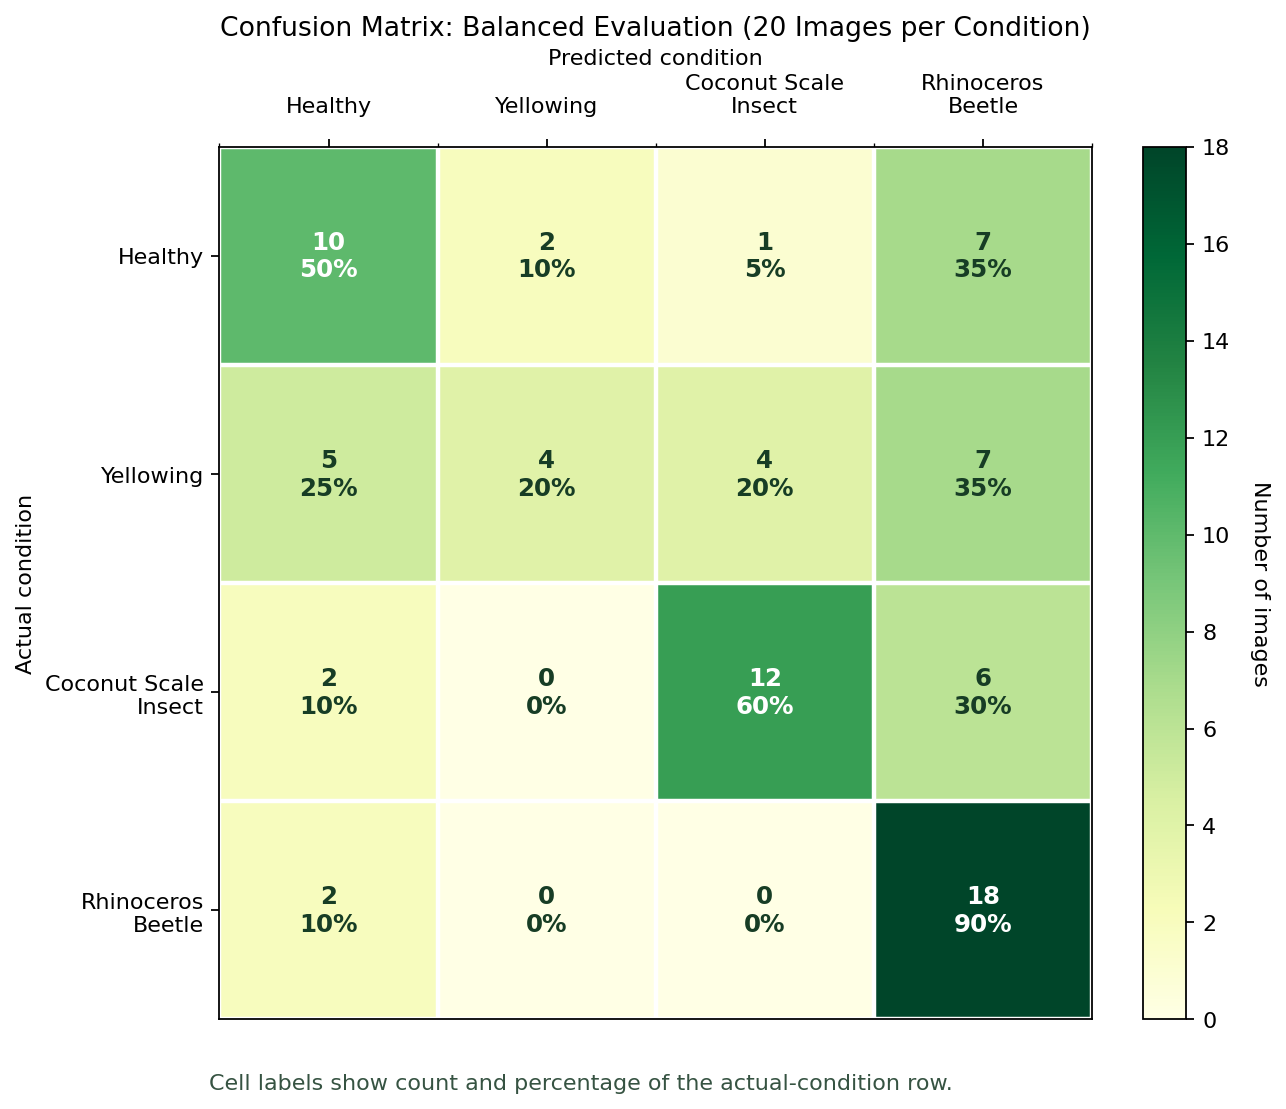

In [ ]:
external_status = external_test_status(
    EXTERNAL_TEST_DIR,
    expected_per_class=TARGET_IMAGES_PER_CLASS,
    reference_dataset=INTERNAL_TEST_DATASET_DIR,
)
print(json.dumps(external_status, indent=2))
if not external_status['audited']:
    raise RuntimeError('Evaluation stopped: resolve the external-image audit findings first.')

external_report = evaluate_api(
    TFLITE_PATH, LABEL_CONFIG_PATH, EXTERNAL_TEST_DIR, split=None, runtime='tflite'
)
internal_report = evaluate_api(
    TFLITE_PATH, LABEL_CONFIG_PATH, INTERNAL_TEST_DATASET_DIR, split='test', runtime='tflite'
)
balanced_report = build_balanced_report(internal_report['predictions'], external_report['predictions'])
balanced_report.update(
    model_sha256=internal_report['model_sha256'],
    config_sha256=internal_report['config_sha256'],
    runtime='tflite',
    external_status=external_status,
    excluded_duplicate_approval={
        'id': 'Y04',
        'reason': 'Exact pixel duplicate of Yellowing/yellowing_approved_lucid_02.jpg; it is not counted twice.',
    },
)
(OUTPUT_DIR / 'evaluation_balanced_20_per_class.json').write_text(
    json.dumps(balanced_report, indent=2) + '\n', encoding='utf-8'
)
with (OUTPUT_DIR / 'per_class_metrics_balanced_20_per_class.csv').open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=['class', 'precision', 'recall', 'f1', 'support'])
    writer.writeheader()
    writer.writerows({'class': name, **row} for name, row in balanced_report['per_class'].items())
with (OUTPUT_DIR / 'confusion_matrix_balanced_20_per_class.csv').open('w', newline='', encoding='utf-8') as handle:
    writer = csv.writer(handle)
    writer.writerow(['actual / predicted', *CLASSES])
    writer.writerows([name, *row] for name, row in zip(CLASSES, balanced_report['confusion_matrix']))

display_f1_score_table(balanced_report, 'Balanced 20 images per condition (TensorFlow Lite website runtime)')
display_confusion_matrix(balanced_report, 'Balanced Evaluation (20 Images per Condition)')
print('Composition:', json.dumps(balanced_report['composition_by_class'], indent=2))
print('Saved:', OUTPUT_DIR / 'evaluation_balanced_20_per_class.json')